All links -

Dataset: https://drive.google.com/drive/folders/1zRjOt0mEd3b55mfztDL7DJTHqKiv3a4_?usp=sharing

My best traiend model: https://drive.google.com/drive/folders/1VPtuJSY32kQv6jnbzaUcx7V9MDVCkDCX?usp=sharing

Dataset 8 Astana Test Images: https://drive.google.com/drive/folders/1QFbJYjlL01d2tah__bTQd7TWBtCEklMO?usp=sharing

In [1]:
!pip install -U "numpy>=2.0,<2.3" "ultralytics>=8.3.20" "opencv-python-headless>=4.10,<4.13" -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 112.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 46.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

from ultralytics import YOLO
import os, glob, random, yaml
from IPython.display import Image, display

DATA_ROOT = "/content/drive/MyDrive/Car_Detection_DATA"
DATA_YAML = f"{DATA_ROOT}/data.yaml"
assert os.path.exists(DATA_YAML), f"data.yaml not found at {DATA_YAML}"
print(open(DATA_YAML).read())


def count_items(split):
    import glob, os
    imgs = glob.glob(f"{DATA_ROOT}/{split}/images/*")
    labels = glob.glob(f"{DATA_ROOT}/{split}/labels/*.txt")
    return split, len(imgs), len(labels)

for split in ["train","valid","test"]:
    if os.path.isdir(f"{DATA_ROOT}/{split}"):
        print(count_items(split))

def peek_labels(n=3):
    import glob, os
    label_files = glob.glob(f"{DATA_ROOT}/train/labels/*.txt")[:n]
    for fp in label_files:
        with open(fp) as f:
            lines = [ln.strip() for ln in f.readlines() if ln.strip()]
        print("—", os.path.basename(fp), "->", lines[:2])
peek_labels()


Mounted at /content/drive
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 23
names: ['auto', 'bicycle', 'bike', 'board', 'building', 'bus', 'car', 'cars', 'divider', 'milestone', 'motor', 'motorbike', 'person', 'rider', 'signboard', 'stop sign', 'street light', 'tower', 'tractor', 'traffic light', 'tree', 'truck', 'van']

roboflow:
  workspace: rashmi-9hrwv
  project: vehicle-detection-in-different-environmental-conditions
  version: 3
  license: Public Domain
  url: https://universe.roboflow.com/rashmi-9hrwv/vehicle-detection-in-different-environmental-conditions/dataset/3
('train', 14026, 14019)
('valid', 1334, 1334)
('test', 667, 667)
— 12-11-2021-5004056_

In [ ]:
import torch, platform, subprocess, os
print("Python", platform.python_version())
print("Torch", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    !nvidia-smi -L


Python 3.12.11
Torch 2.8.0+cu126
CUDA available: True
GPU: NVIDIA L4
GPU 0: NVIDIA L4 (UUID: GPU-d3e2c9d8-0de1-2393-9463-10bb95848de4)


In [ ]:
from ultralytics import YOLO
import torch
print("GPU:", torch.cuda.get_device_name(0))
torch.backends.cudnn.benchmark = True

DATA_YAML = "/content/drive/MyDrive/Car_Detection_DATA/data.yaml"
model = YOLO("yolov8s.pt")

results = model.train(
    data=DATA_YAML,
    device=0,
    epochs=25,
    imgsz=512,
    batch=96,
    workers=8,
    cache="ram",
    rect=True,
    val=False,
    amp=True,
    deterministic=False,
    mosaic=0.0, mixup=0.0,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    erasing=0.0,
    auto_augment="",
    patience=8,
    plots=False,
    project="/content/drive/MyDrive/YOLO_runs",
    name="car_det_v8s_a100",
    exist_ok=True
)

print("Run dir:", results.save_dir)


GPU: NVIDIA L4
Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=, batch=96, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Car_Detection_DATA/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=False, name=car_det_v8s_a100, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=8, persp

In [ ]:
from ultralytics import YOLO
model = YOLO('yolov10m.pt')
metrics = model.val(data='/content/drive/MyDrive/Car_Detection_DATA/data.yaml', imgsz=960, conf=0.001, plots=True)


Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
YOLOv10m summary (fused): 136 layers, 15,359,488 parameters, 0 gradients, 59.1 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 28.3±9.4 MB/s, size: 43.4 KB)
val: Scanning /content/drive/MyDrive/Car_Detection_DATA/valid/labels.cache... 1334 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1334/1334 1.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 1.9it/s 43.4s
                   all       1334       4204      0.677     0.0613     0.0595     0.0401
                person          7         10          0          0          0          0
               bicycle         11         11      0.727      0.909      0.898      0.609
                   car         22         49          0          0   4.52e-05    1.7e-05
            motorcycle          3          3          0          0          0          0
              ai

In [ ]:
metrics = model.val(data=DATA_YAML, split="test", imgsz=640, batch=64, device=0)
print("mAP50-95:", float(metrics.box.map), "| mAP50:", float(metrics.box.map50))

import os, glob
run_dir = str(results.save_dir)
print("Best weights:", os.path.join(run_dir, "weights", "best.pt"))


Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
Model summary (fused): 72 layers, 11,134,485 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 0.1±0.0 MB/s, size: 50.8 KB)
val: Scanning /content/drive/MyDrive/Car_Detection_DATA/test/labels... 667 images, 67 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 667/667 7.6it/s 1:28
val: New cache created: /content/drive/MyDrive/Car_Detection_DATA/test/labels.cache
val: Caching images (0.8GB RAM): 100% ━━━━━━━━━━━━ 667/667 509.6it/s 1.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 0.9it/s 12.3s
                   all        667       2022       0.34      0.231      0.186      0.134
                  auto          2          3          1          0          0          0
               bicycle          7          7      0.499      0.714      0.614      0.382
                  bike         12         19      0.2

Downloading Model to the Google Drive

In [ ]:
# === Save trained YOLO weights to Google Drive ===
import os, glob, shutil, datetime
from google.colab import drive

drive.mount('/content/drive', force_remount=False)


try:
    run_dir = str(results.save_dir)
except NameError:
    cand = glob.glob("/content/runs/*/*")
    assert cand, "No YOLO runs found under /content/runs/"
    run_dir = max(cand, key=os.path.getmtime)

weights_dir = os.path.join(run_dir, "weights")
best_pt = os.path.join(weights_dir, "best.pt")
last_pt = os.path.join(weights_dir, "last.pt")
src_pt = best_pt if os.path.exists(best_pt) else last_pt
assert os.path.exists(src_pt), "No best.pt or last.pt found in run weights."

# Making a versioned destination on Drive
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
dst_dir = f"/content/drive/MyDrive/YOLO_models/car_det_v8n_{stamp}"
os.makedirs(dst_dir, exist_ok=True)

# Copy weights and a few useful artifacts
dst_weight = os.path.join(dst_dir, os.path.basename(src_pt))
shutil.copy2(src_pt, dst_weight)

for fn in ["results.png", "results.csv", "args.yaml"]:
    p = os.path.join(run_dir, fn)
    if os.path.exists(p):
        shutil.copy2(p, os.path.join(dst_dir, os.path.basename(p)))

print("Saved model to:", dst_weight)
print("Run folder was:", run_dir)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved model to: /content/drive/MyDrive/YOLO_models/car_det_v8n_20250917_142726/best.pt
Run folder was: /content/drive/MyDrive/YOLO_runs/car_det_v8s_a100


In [ ]:
from ultralytics import YOLO, settings
m = YOLO(dst_weight)
onnx_path = m.export(format="onnx", dynamic=True, opset=12, imgsz=640)
shutil.move(onnx_path, os.path.join(dst_dir, os.path.basename(onnx_path)))
print("Exported ONNX to:", os.path.join(dst_dir, os.path.basename(onnx_path)))


Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 72 layers, 11,134,485 parameters, 0 gradients, 28.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/YOLO_models/car_det_v8n_20250917_142726/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 27, 8400) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0', 'onnxslim>=0.1.67', 'onnxruntime-gpu'] not found, attempting AutoUpdate...

requirements: AutoUpdate success ✅ 4.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.19.0 opset 12...
ONNX: slimming with onnxslim 0.1.68...
ONNX: export success ✅ 8.3s, saved as '/content/drive/MyDrive/YOLO_models/car_det_v8n_20250917_142726/best.onnx' (42.6 MB)

Export complete (8.8s)
Results saved 

In [ ]:
metrics = model.val(data=DATA_YAML, imgsz=640, batch=32, device=0)
print(metrics)


Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 26.0±10.7 MB/s, size: 44.1 KB)
val: Scanning /content/drive/MyDrive/Car_Detection_DATA/valid/labels.cache... 1334 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1334/1334 1.9Mit/s 0.0s
val: Caching images (1.5GB RAM): 100% ━━━━━━━━━━━━ 1334/1334 493.9it/s 2.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 2.6it/s 16.0s
                   all       1334       4204      0.788      0.193      0.196      0.123
                  auto          7         10          1          0      0.164     0.0494
               bicycle         11         11      0.838      0.818      0.782      0.483
                  bike         22         49      0.645      0.223      0.225      0.101
                 board          3          3          1          0          0          0
              building   

Model Prediction and Results

Using test images from: /content/drive/MyDrive/Car_Detection_DATA/test/images

image 1/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/01705c36-8993db9f_jpg.rf.39bc156da5123b03c7e56b1af50c138b.jpg: 640x640 1 person, 1 truck, 7.1ms
image 2/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/02346f91-a62c5e01_jpg.rf.d60272007d6b99eb0d79109caa6098a0.jpg: 640x640 (no detections), 7.5ms
image 3/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/04076a65-79b349d4_jpg.rf.ceaf56c0f27a268bf0a834c6909325fa.jpg: 640x640 (no detections), 7.7ms
image 4/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/040dfa50-4082932d_jpg.rf.ac9b2f1f9e00f034859be656455ba64e.jpg: 640x640 2 trucks, 7.3ms
image 5/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/041dc63f-7fe29e93_jpg.rf.3cdf6c3459b20a79520222827856d662.jpg: 640x640 (no detections), 7.1ms
image 6/667 /content/drive/MyDrive/Car_Detection_DATA/test/images/04629c39-1d564d8a_jpg.rf.6bd54810804c59c9631cbab90891c424.jp

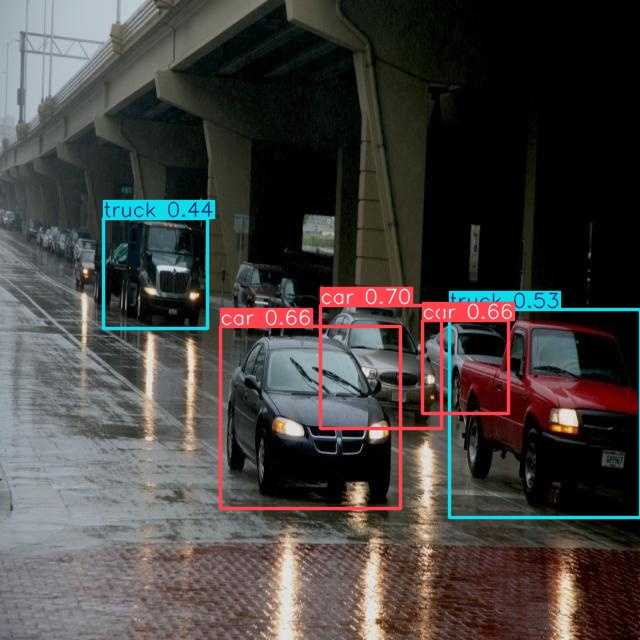

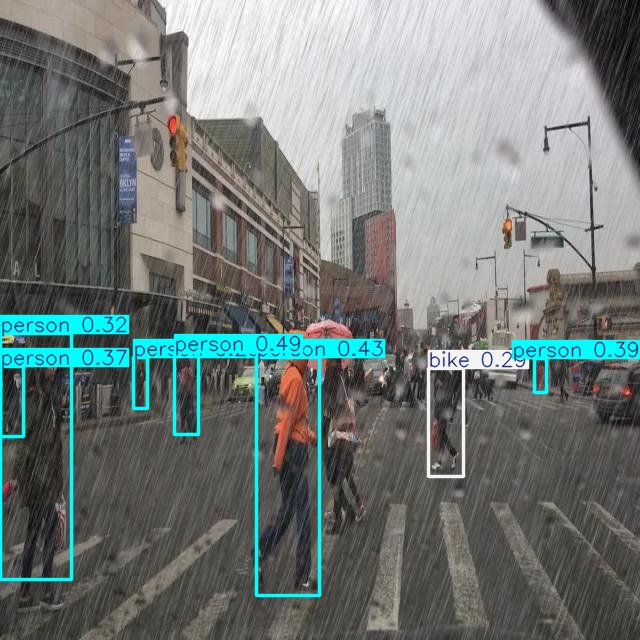

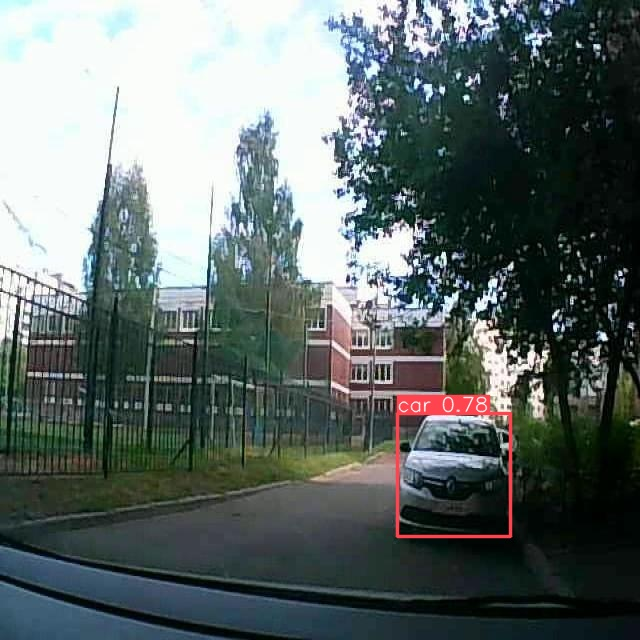

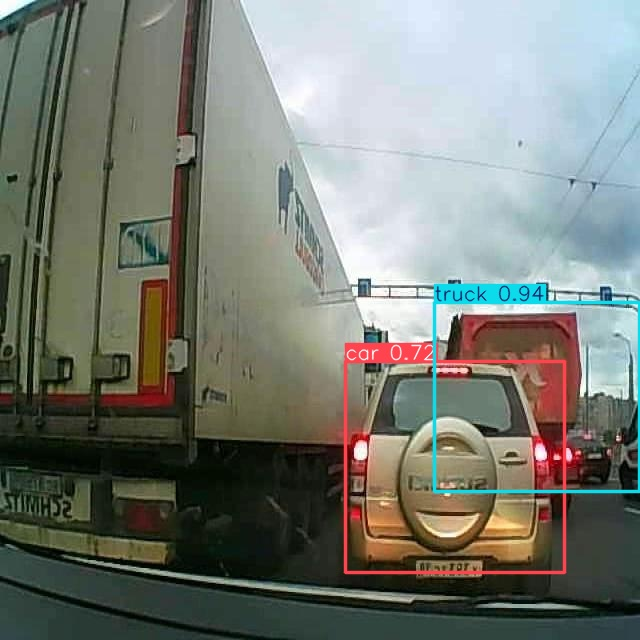

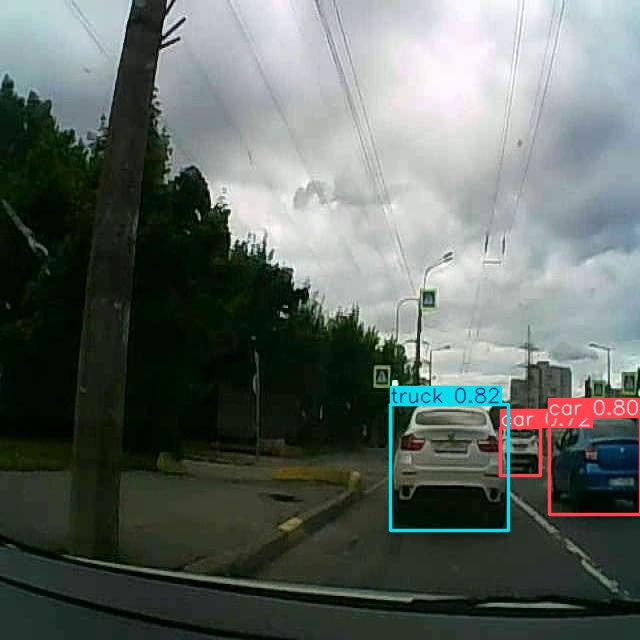

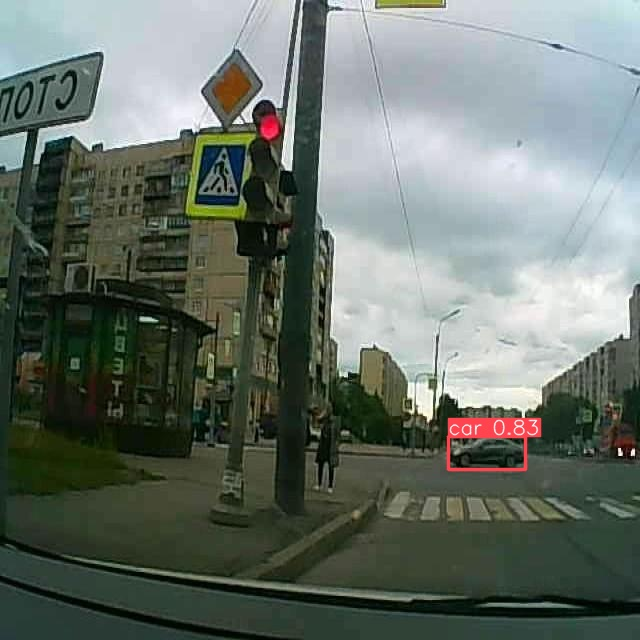

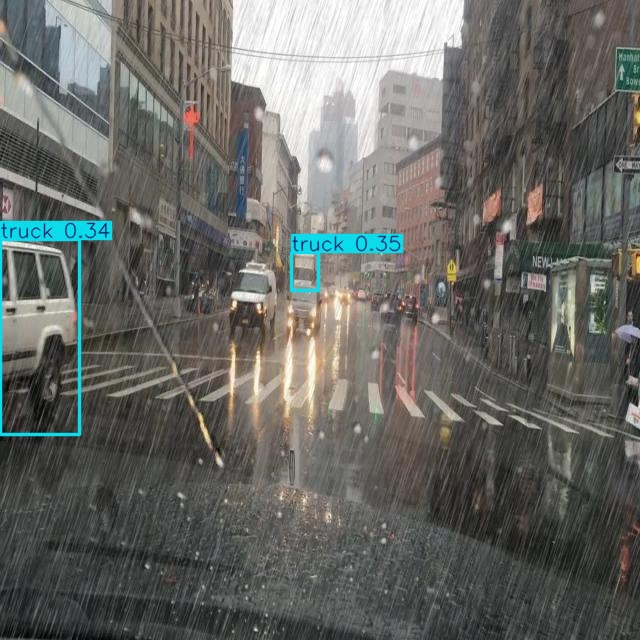

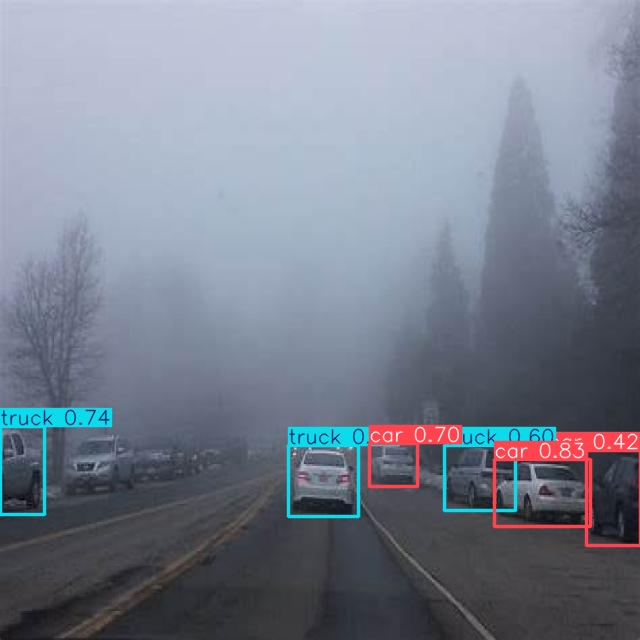

In [3]:
from ultralytics import YOLO
from IPython.display import Image, display
from pathlib import Path

# Load trained model
BEST_PT = "/content/drive/MyDrive/YOLO_runs/car_det_v8s_a100/weights/best.pt"
model = YOLO(BEST_PT)

test_images_dir = Path("/content/drive/MyDrive/Car_Detection_DATA/test/images")
print("Using test images from:", test_images_dir)


pred = model.predict(
    source=str(test_images_dir),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True
)

# Some results
pred_dir = Path(pred[0].save_dir)
print("Annotated images saved to:", pred_dir)

for p in list(pred_dir.glob("*.jpg"))[:8]:  # show first 8
    display(Image(filename=str(p)))


Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
Model summary (fused): 72 layers, 11,134,485 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 30.1±16.9 MB/s, size: 44.2 KB)
val: Scanning /content/drive/MyDrive/Car_Detection_DATA/test/labels.cache... 667 images, 67 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 667/667 1.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 5.2it/s 8.1s
                   all        667       2022       0.34      0.231      0.186      0.134
                  auto          2          3          1          0          0          0
               bicycle          7          7        0.5      0.714      0.613      0.382
                  bike         12         19      0.205      0.158      0.147      0.103
                 board          2          2          0          0          0          0
              building   

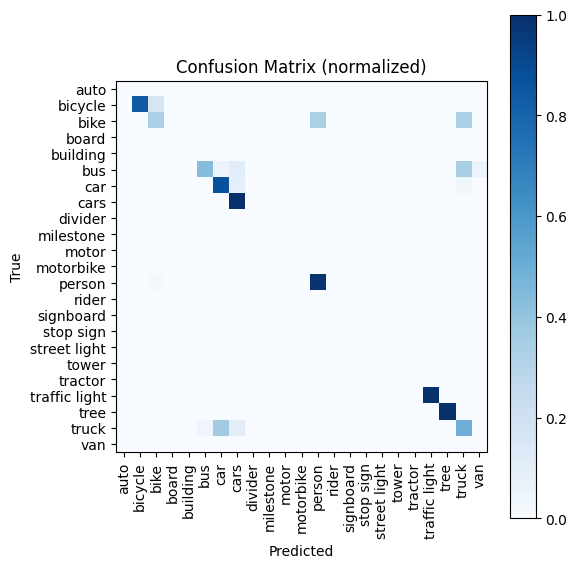

In [24]:
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt

# Load your trained weights
BEST_PT = "/content/drive/MyDrive/YOLO_runs/car_det_v8s_a100/weights/best.pt"
model = YOLO(BEST_PT)

DATA_YAML = "/content/drive/MyDrive/Car_Detection_DATA/data.yaml"

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    device=0,
    plots=True
)

print("mAP@0.5 :", metrics.box.map50)
print("mAP@0.5:0.95 :", metrics.box.map)

cm = metrics.confusion_matrix.matrix.copy()
names = [metrics.names[i] for i in range(len(metrics.names))]

if cm.shape[0] == len(names) + 1:
    cm = cm[:-1, :-1]

cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1e-9)

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap="Blues")
plt.xticks(np.arange(len(names)), names, rotation=90)
plt.yticks(np.arange(len(names)), names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (normalized)")
plt.colorbar()
plt.tight_layout()
plt.show()


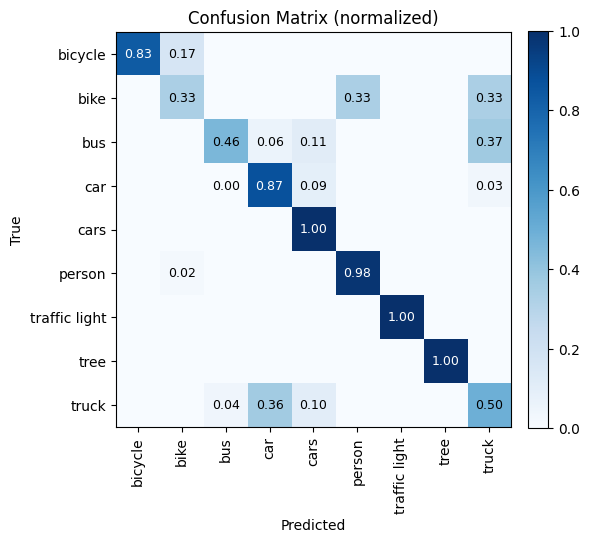

✅ Confusion matrix saved to: /content/drive/MyDrive/confusion_matrix_selected.png


In [34]:
cm = metrics.confusion_matrix.matrix.copy()
names = [metrics.names[i] for i in range(len(metrics.names))]
if cm.shape[0] == len(names) + 1:
    cm = cm[:-1, :-1]


# classes to keep
keep = [
    "bicycle", "bike", "bus", "car", "cars",
    "person", "traffic light", "tree", "truck"
]

idx = [names.index(c) for c in keep if c in names]

cm = cm[np.ix_(idx, idx)]
names = [names[i] for i in idx]

# normalise by true class (row-wise)
cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1e-9)

# --- plot with per-cell scores ---
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(np.arange(len(names)))
ax.set_yticks(np.arange(len(names)))
ax.set_xticklabels(names, rotation=90)
ax.set_yticklabels(names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix (normalized)")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        if val == 0:
            continue  # skip pure zeros
        txt_color = "white" if val > 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=9)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# --- save the confusion matrix figure to Google Drive ---
out_path = "/content/drive/MyDrive/confusion_matrix_selected.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
print(f"✅ Confusion matrix saved to: {out_path}")


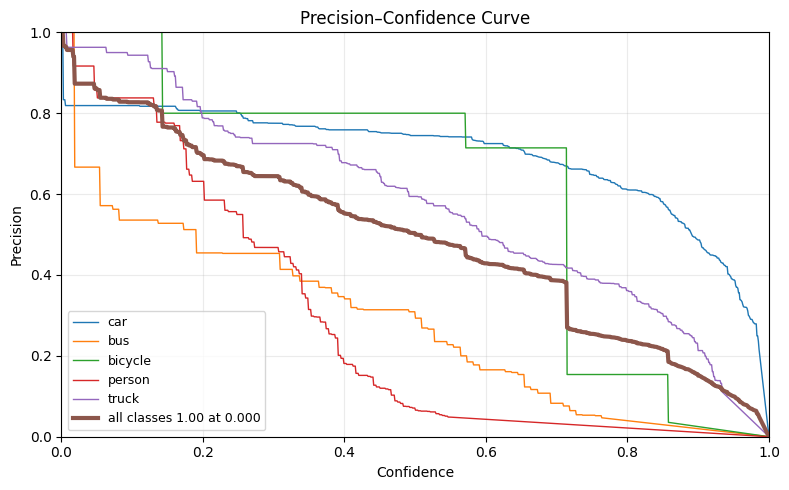

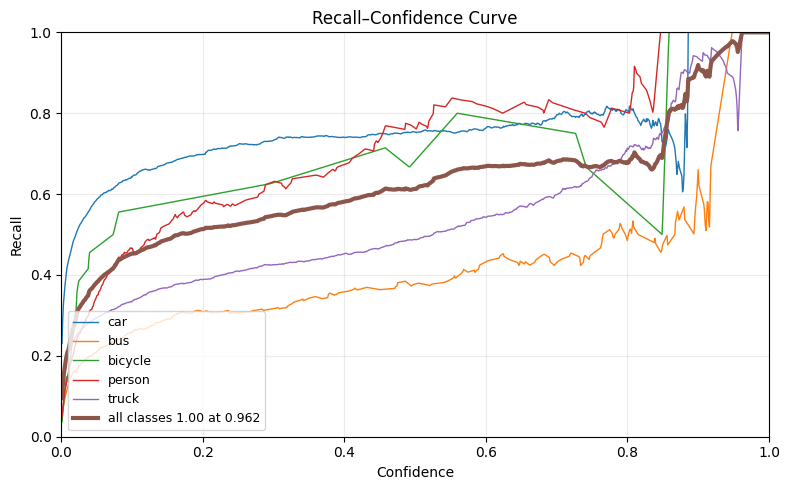

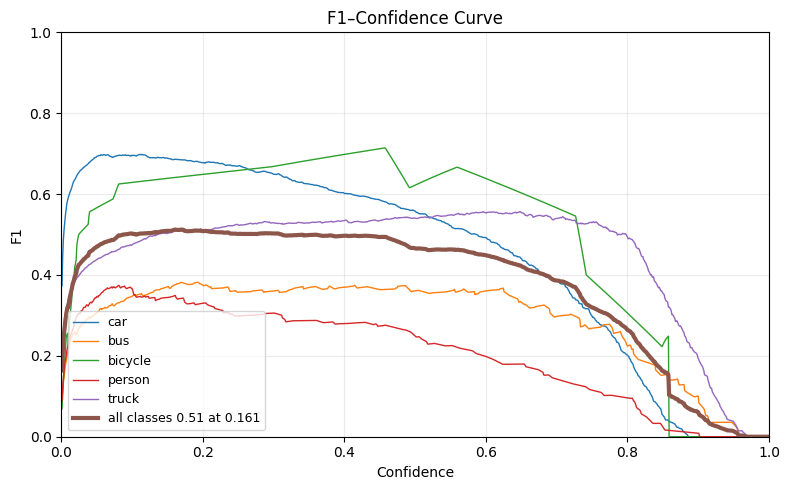

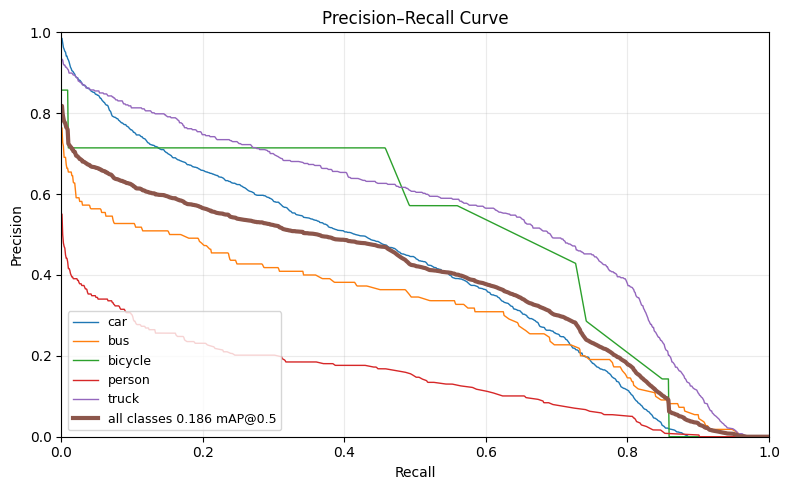

Saved: /content/drive/MyDrive/yolo_eval_curves_png/precision_confidence.png
Saved: /content/drive/MyDrive/yolo_eval_curves_png/recall_confidence.png
Saved: /content/drive/MyDrive/yolo_eval_curves_png/f1_confidence.png
Saved: /content/drive/MyDrive/yolo_eval_curves_png/precision_recall.png


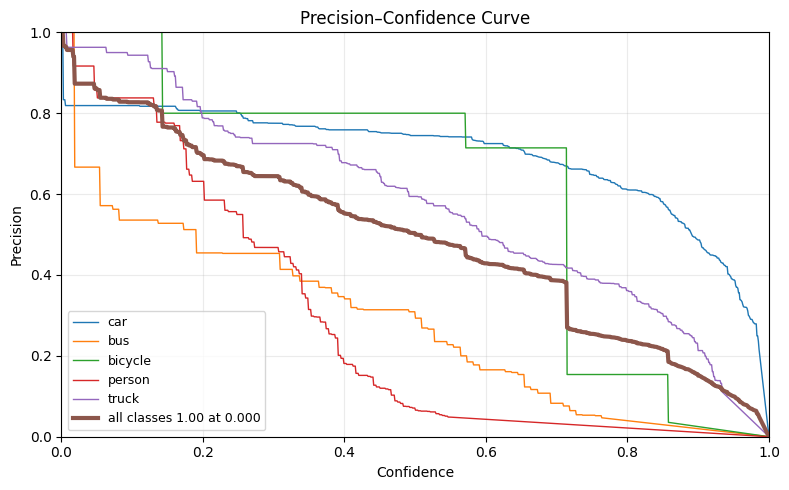

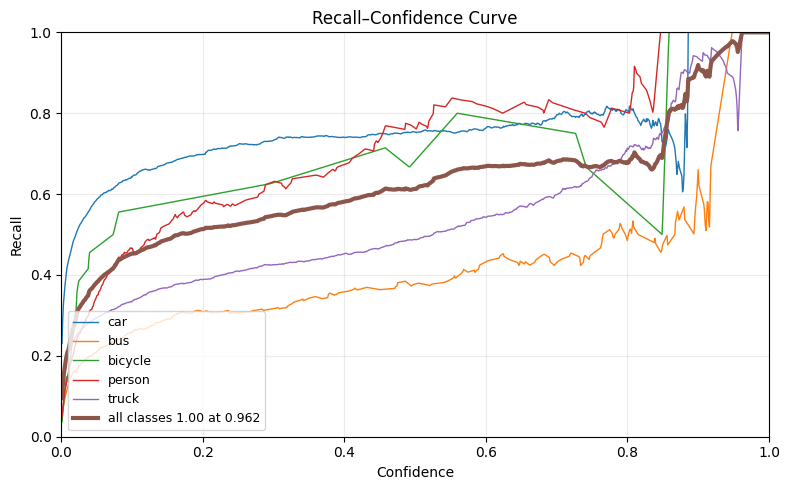

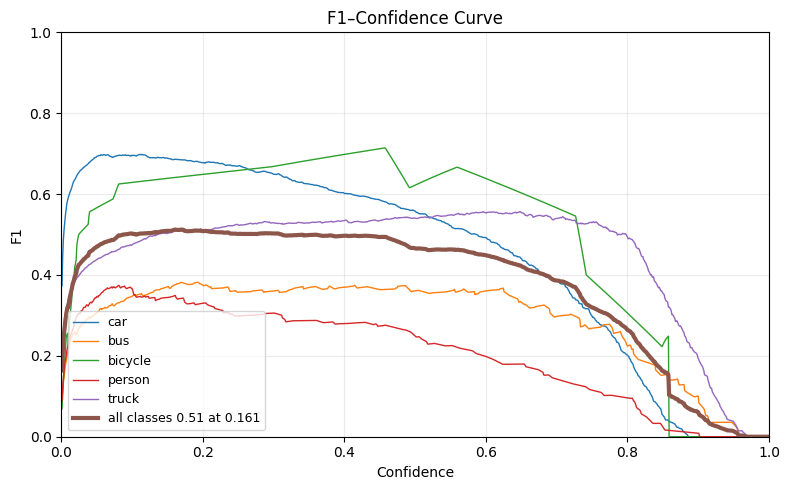

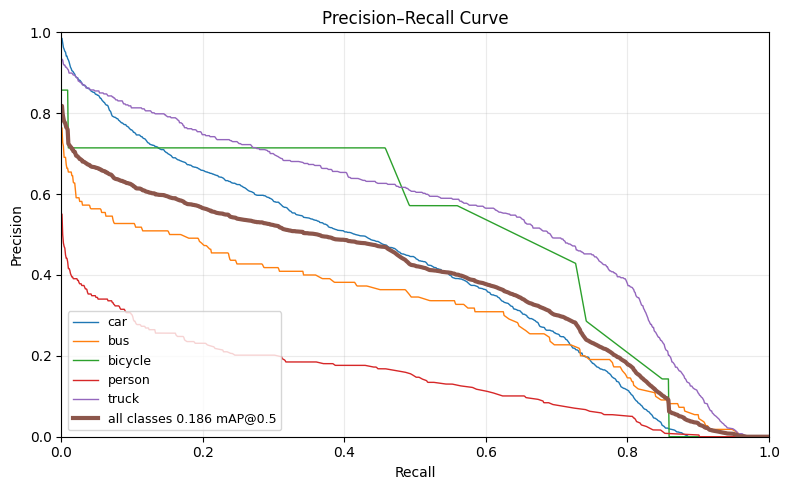

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path


wanted_names = {"person", "bicycle", "car", "bus", "truck"}
names = [metrics.names[i] for i in range(len(metrics.names))]

name_to_id = {n: i for i, n in enumerate(names)}
wanted_ids = [name_to_id[n] for n in wanted_names if n in name_to_id]

ap_idx = np.array(getattr(metrics, "ap_class_index",
                          np.arange(len(names))))
clsid_to_row = {int(cid): r for r, cid in enumerate(ap_idx)}

row_ids = [clsid_to_row[cid] for cid in wanted_ids if cid in clsid_to_row]
row_names = [names[cid] for cid in wanted_ids if cid in clsid_to_row]
assert row_ids, "None of the requested classes appear in the evaluated set."


def make_curve(curve_idx, ylabel, title,
               avg_label_fmt="all classes {val:.2f} at {x:.3f}",
               is_conf_curve=True):
    """Return a matplotlib Figure for the requested curve."""
    x, y_matrix, _, _ = metrics.curves_results[curve_idx]
    y_matrix = np.asarray(y_matrix)
    y_sel = y_matrix[row_ids, :]
    macro = np.nanmean(y_sel, axis=0)

    if is_conf_curve:
        best_i = int(np.nanargmax(macro))
        best_val = float(macro[best_i])
        best_x = float(x[best_i])
        avg_label = avg_label_fmt.format(val=best_val, x=best_x)
    else:
        avg_label = avg_label_fmt.format(val=float(metrics.box.map50))

    fig, ax = plt.subplots(figsize=(8,5))
    for rid, rn in zip(row_ids, row_names):
        ax.plot(x, y_matrix[rid,:], linewidth=1, label=rn)
    ax.plot(x, macro, linewidth=3, label=avg_label)
    ax.set_title(title)
    ax.set_xlabel("Confidence" if is_conf_curve else "Recall")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0,1)
    ax.set_xlim(0,1)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="lower left", fontsize=9)
    fig.tight_layout()
    return fig


fig_precision = make_curve(0, "Precision", "Precision–Confidence Curve", is_conf_curve=True)
fig_recall    = make_curve(2, "Recall",    "Recall–Confidence Curve",    is_conf_curve=True)
fig_f1        = make_curve(1, "F1",        "F1–Confidence Curve",        is_conf_curve=True)
fig_pr        = make_curve(3, "Precision", "Precision–Recall Curve",
                           avg_label_fmt="all classes {val:.3f} mAP@0.5",
                           is_conf_curve=False)

for fig in [fig_precision, fig_recall, fig_f1, fig_pr]:
    display(fig)


save_dir = Path("/content/drive/MyDrive/yolo_eval_curves_png")
save_dir.mkdir(parents=True, exist_ok=True)

fig_map = {
    "precision_confidence.png": fig_precision,
    "recall_confidence.png":    fig_recall,
    "f1_confidence.png":        fig_f1,
    "precision_recall.png":     fig_pr,
}

for fname, fig in fig_map.items():
    fpath = save_dir / fname
    fig.savefig(fpath, dpi=300, bbox_inches="tight")
    print(f"Saved: {fpath}")


In [ ]:
metrics = model.val(
    data="/content/drive/MyDrive/Car_Detection_DATA/data.yaml",
    conf=0.25,
    device=0
)

print(metrics)
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)
print("Per-class mAP:", metrics.box.maps)


Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 16.8±12.9 MB/s, size: 44.9 KB)
val: Scanning /content/drive/MyDrive/Car_Detection_DATA/valid/labels.cache... 1334 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1334/1334 2.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 4.8it/s 17.5s
                   all       1334       4204       0.23      0.184        0.2      0.137
                  auto          7         10          0          0          0          0
               bicycle         11         11        0.9      0.818      0.864      0.592
                  bike         22         49      0.625      0.204        0.4      0.217
                 board          3          3          0          0          0          0
              building         19         31          0          0          0          0
            

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

image 1/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_1.jpeg: 384x640 27 cars, 2 buss, 1 truck, 11.0ms
image 2/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_2.jpeg: 448x640 8 cars, 2 trucks, 10.4ms
image 3/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_3.jpeg: 448x640 24 cars, 1 truck, 8.3ms
image 4/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_4.jpg: 384x640 1 person, 27 cars, 4 trucks, 8.9ms
image 5/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_5.jpg: 384x640 20 cars, 2 buss, 2 trucks, 8.6ms
image 6/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_6.jpeg: 384x640 5 persons, 24 cars, 1 truck, 8.4ms
image 7/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_7.jpeg: 480x640 15 cars, 2 buss, 1 truck, 10.2ms
image 8/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_8.png: 384x640 1 person, 22 cars, 2 trucks, 9.3ms
Speed: 2.1ms preproc

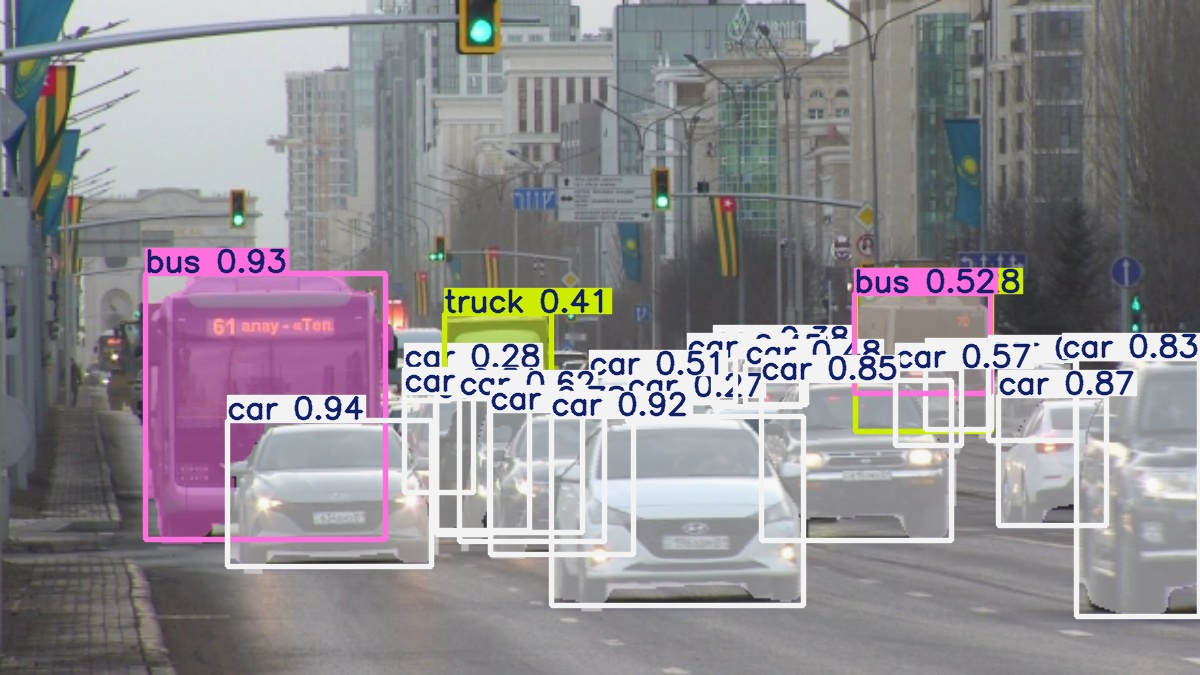

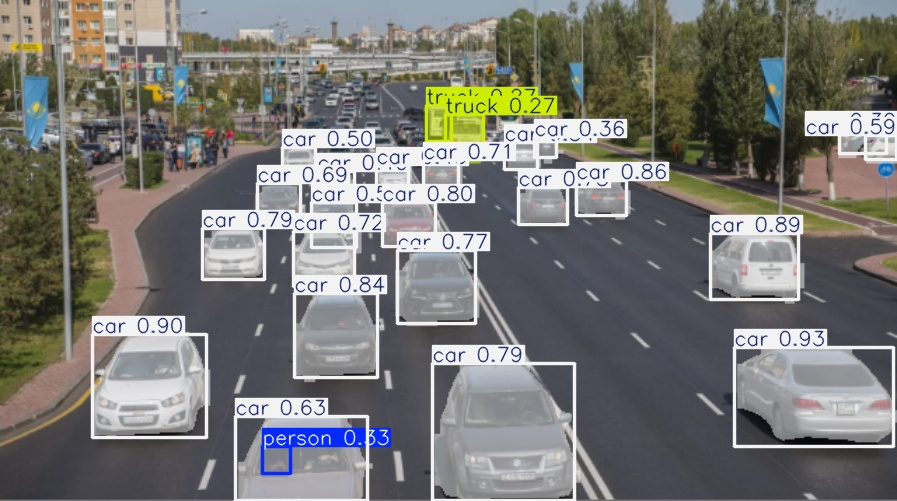

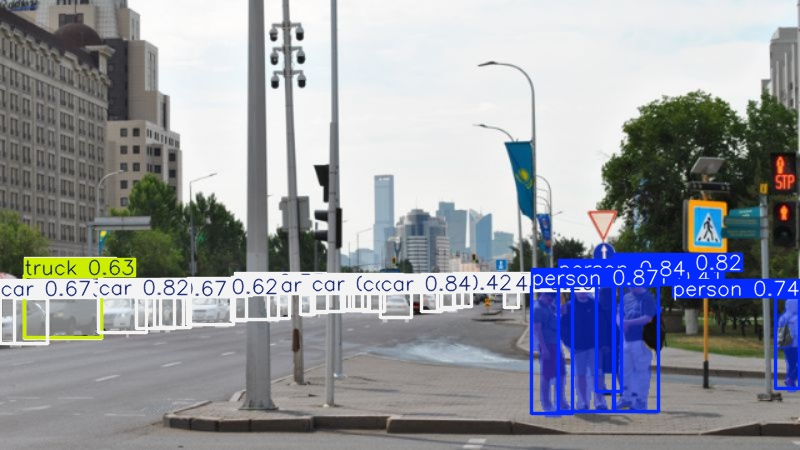

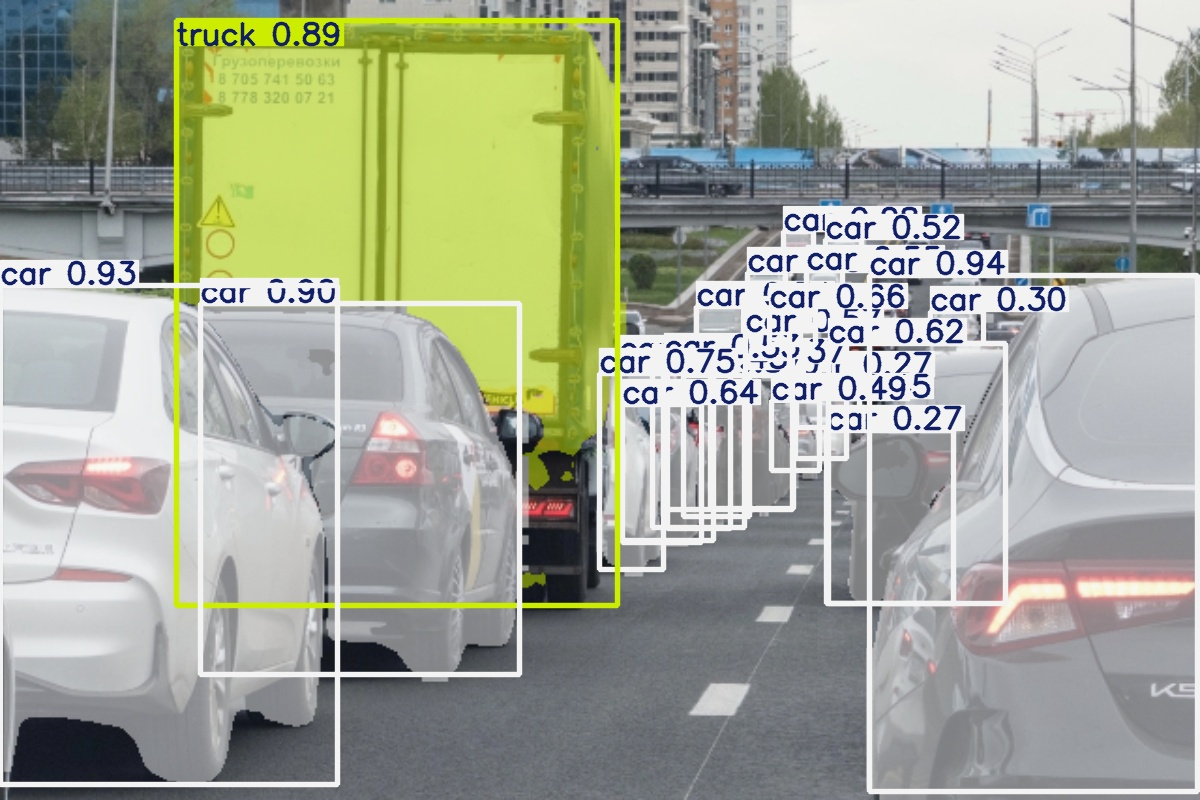

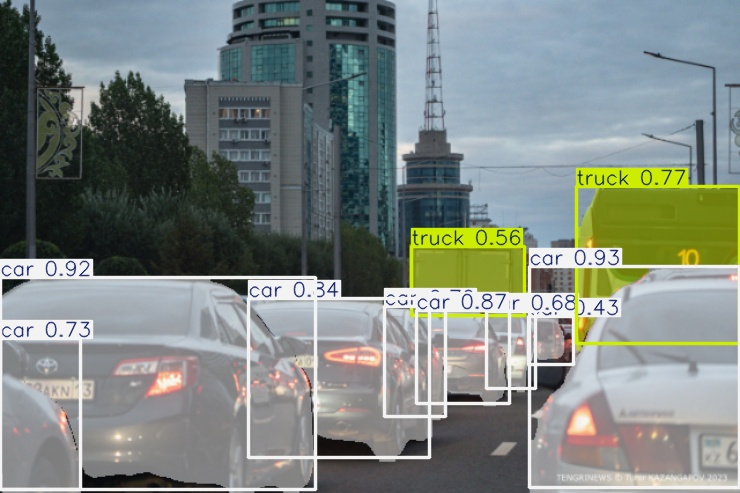

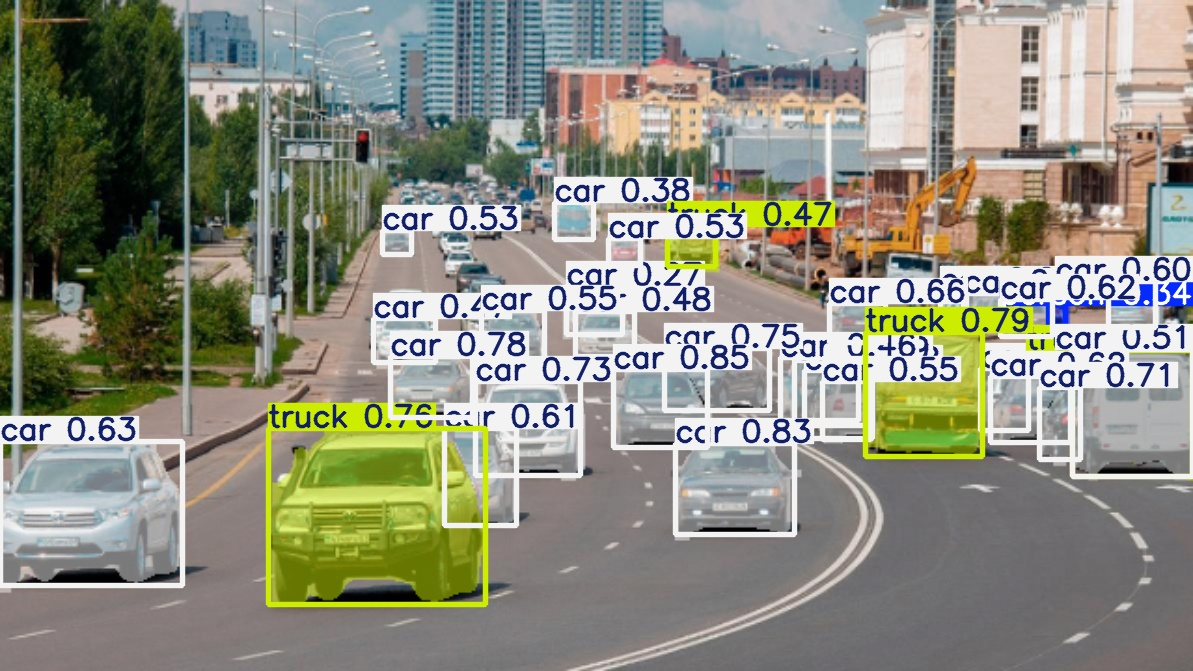

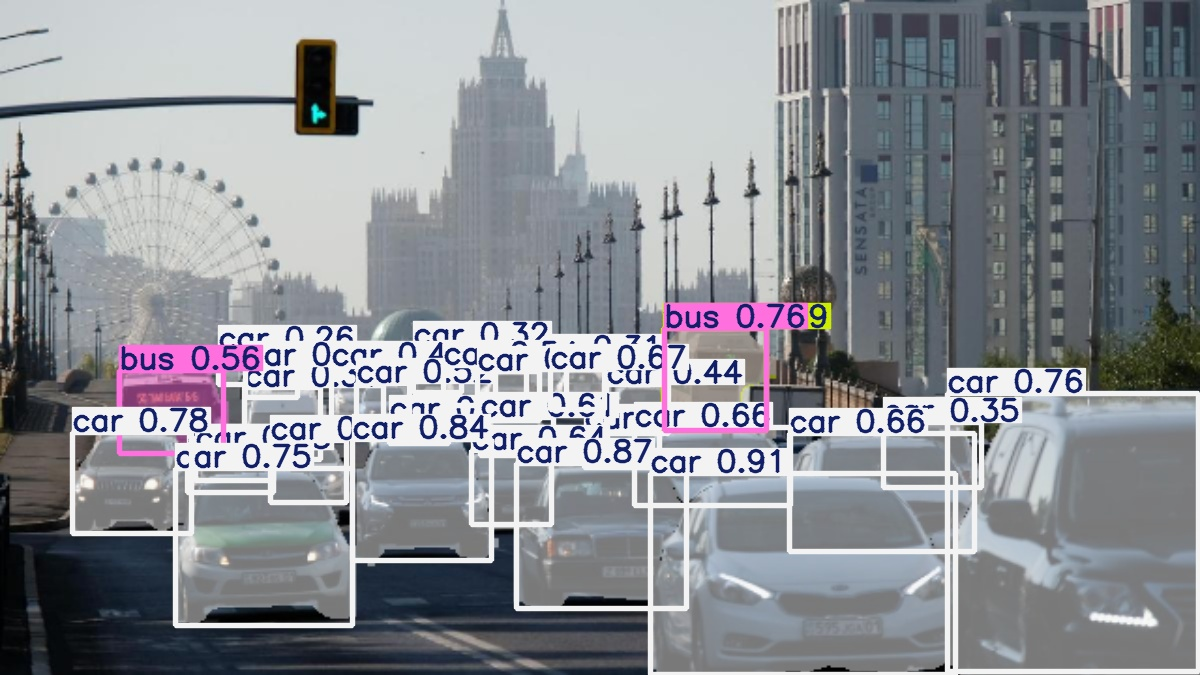

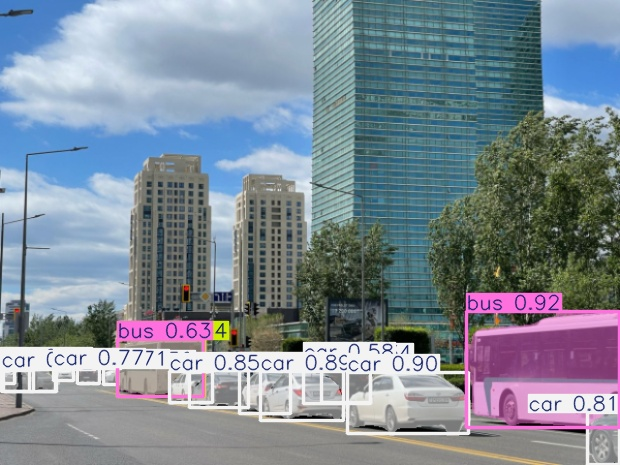

Polygon label files saved under: /content/runs/segment/predict2/labels


In [20]:
!pip -q install "ultralytics>=8.3.20" opencv-python-headless

from ultralytics import YOLO
from google.colab import drive
from pathlib import Path
from IPython.display import Image, display

drive.mount('/content/drive', force_remount=False)

IMG_DIR = Path("/content/drive/MyDrive/DATA_Test")
assert IMG_DIR.exists(), f"Folder not found: {IMG_DIR}"

# --- COCO-pretrained SEGMENTATION model ---
model = YOLO("yolov8s-seg.pt")

# COCO class IDs for the required categories:
# 0=person, 1=bicycle, 2=car, 5=bus, 7=truck
wanted_classes = [0, 1, 2, 5, 7]

# --- Run segmentation only for these classes ---
pred = model.predict(
    source=str(IMG_DIR),
    imgsz=640,
    conf=0.25,
    device=0,
    classes=wanted_classes,
    save=True,
    save_txt=True,
    save_conf=True
)

# --- Show a few results inline ---
out_dir = Path(pred[0].save_dir)
print("Segmented outputs saved to:", out_dir)
for p in list(out_dir.glob("*.jpg"))[:8]:
    display(Image(filename=str(p)))
print("Polygon label files saved under:", out_dir / "labels")


Results of model on Images from Astana


image 1/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_1.jpeg: 384x640 11 cars, 1 traffic light, 9.0ms
image 2/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_2.jpeg: 448x640 2 cars, 3 trucks, 7.6ms
image 3/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_3.jpeg: 448x640 2 cars, 7.0ms
image 4/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_4.jpg: 384x640 1 bus, 13 cars, 3 trucks, 7.8ms
image 5/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_5.jpg: 384x640 1 bus, 8 cars, 7.1ms
image 6/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_6.jpeg: 384x640 4 cars, 5 persons, 4 trucks, 7.5ms
image 7/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_7.jpeg: 480x640 2 buss, 11 cars, 7.9ms
image 8/8 /content/drive/MyDrive/DATA_Test/Astana_car_test_8.png: 384x640 8 cars, 5 carss, 3 trucks, 7.3ms
Speed: 2.0ms preprocess, 7.7ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict3
Colab output dir: /content/runs/detect/predic

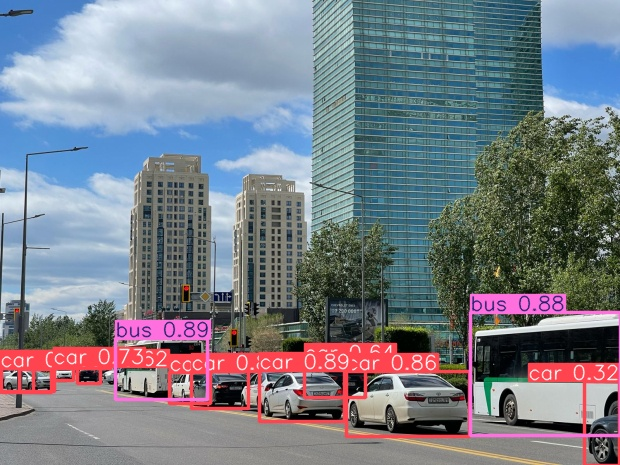

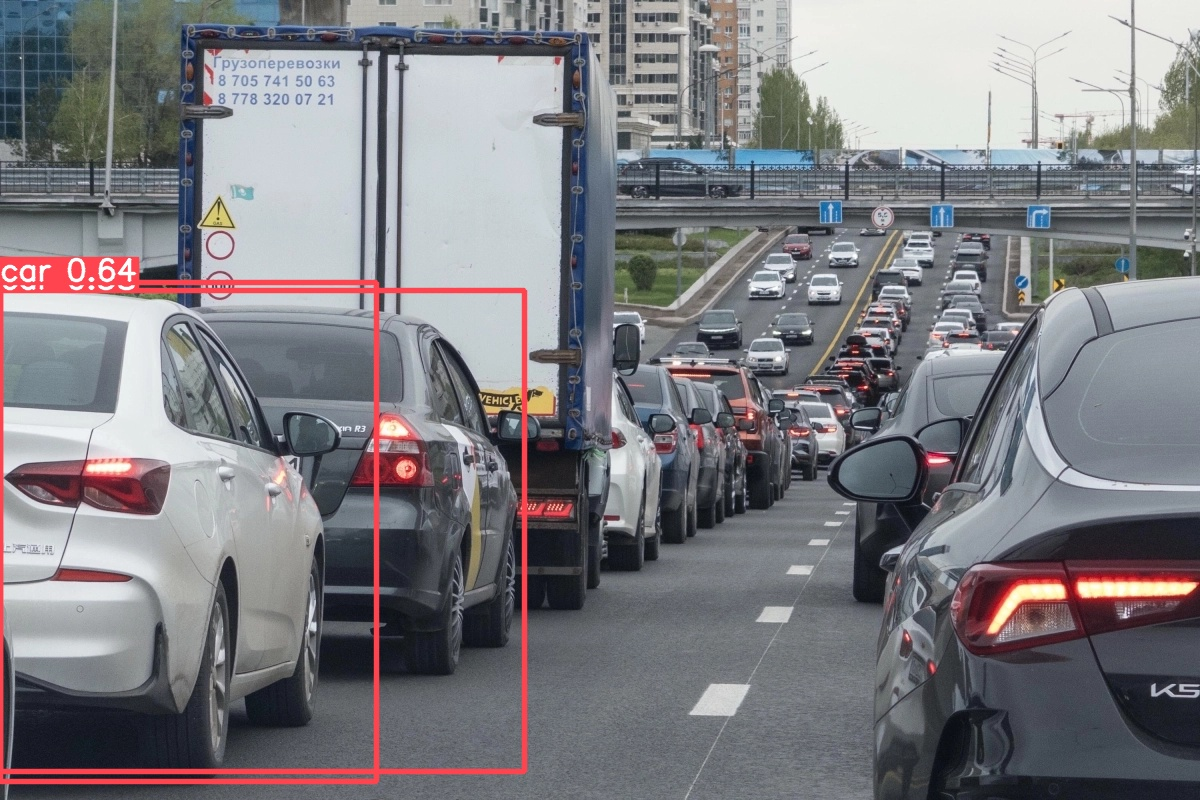

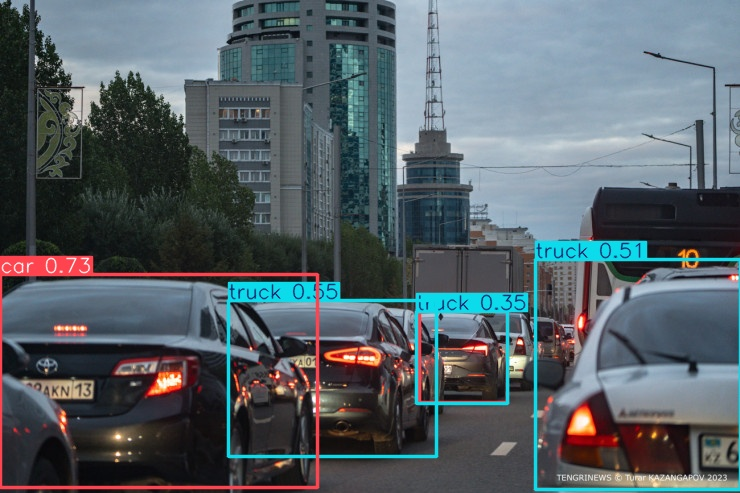

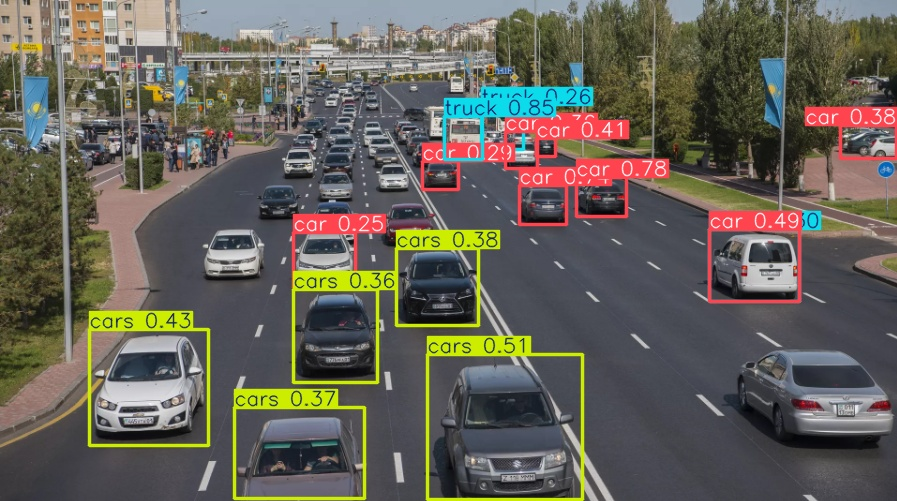

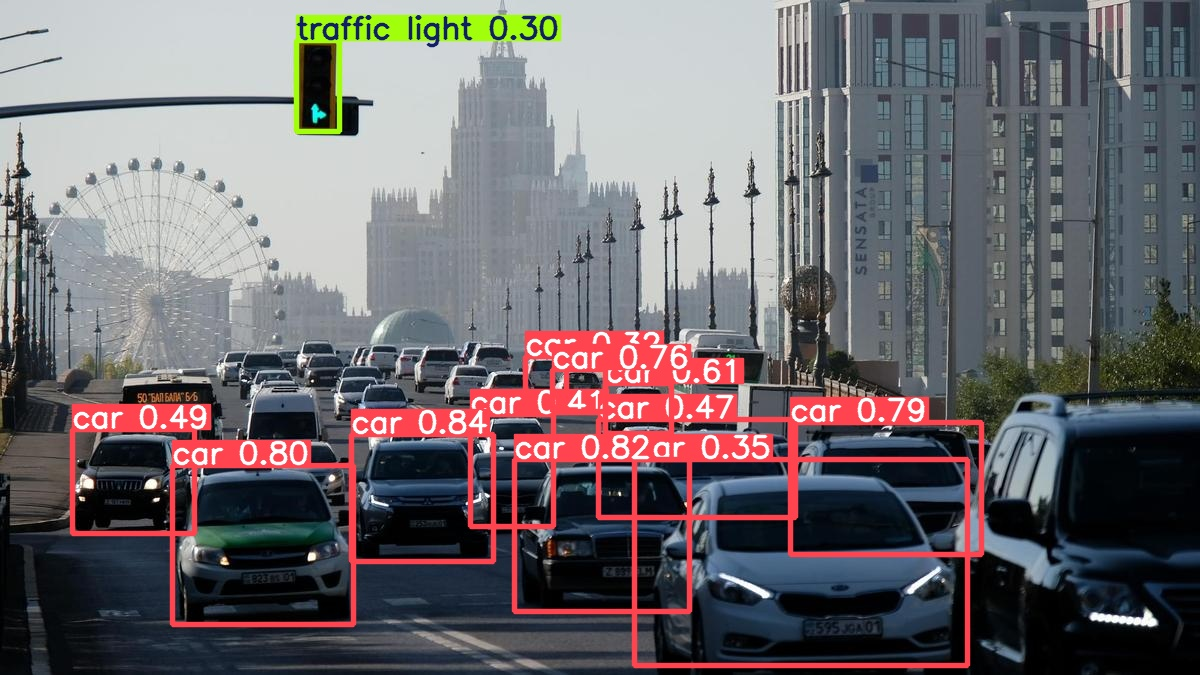

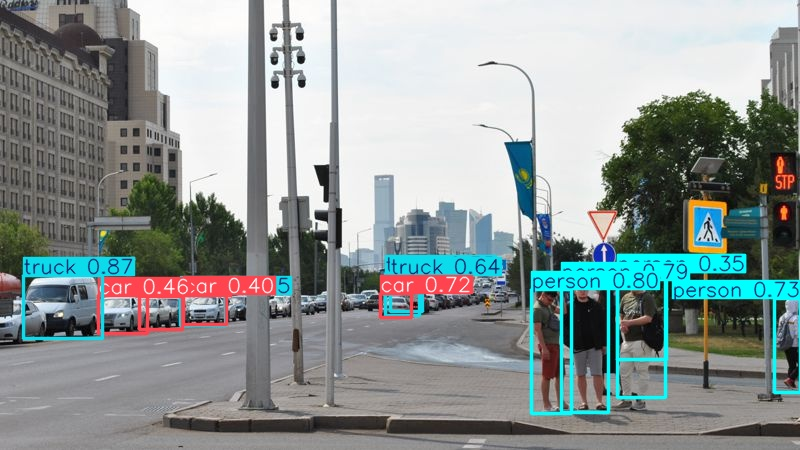

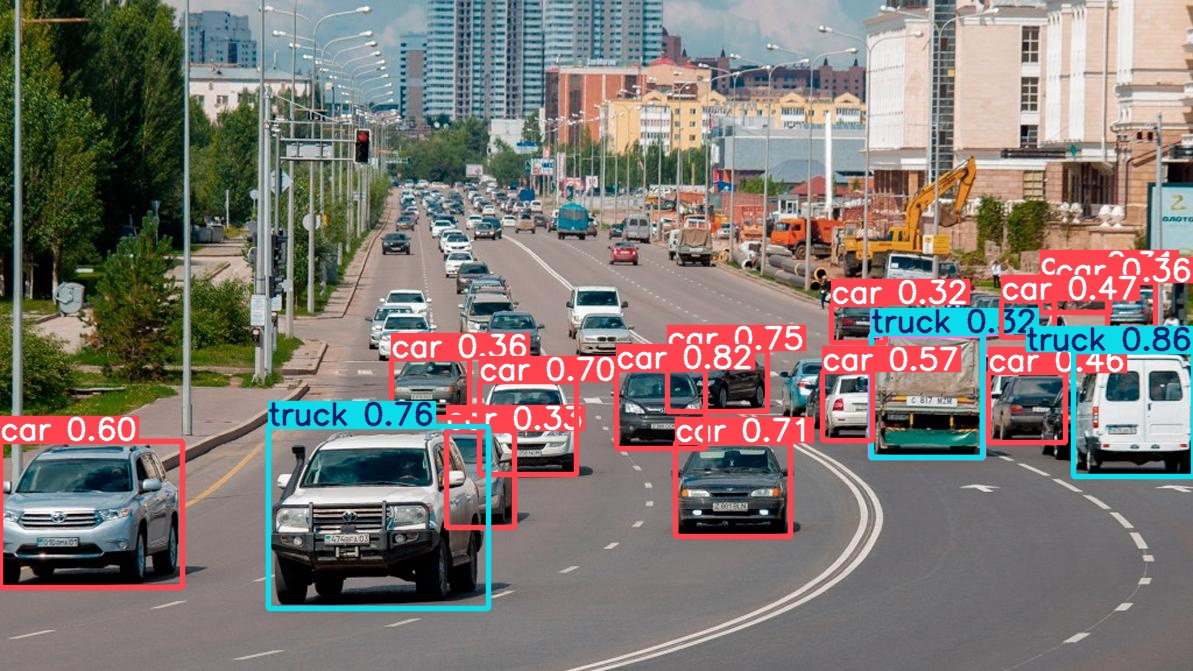

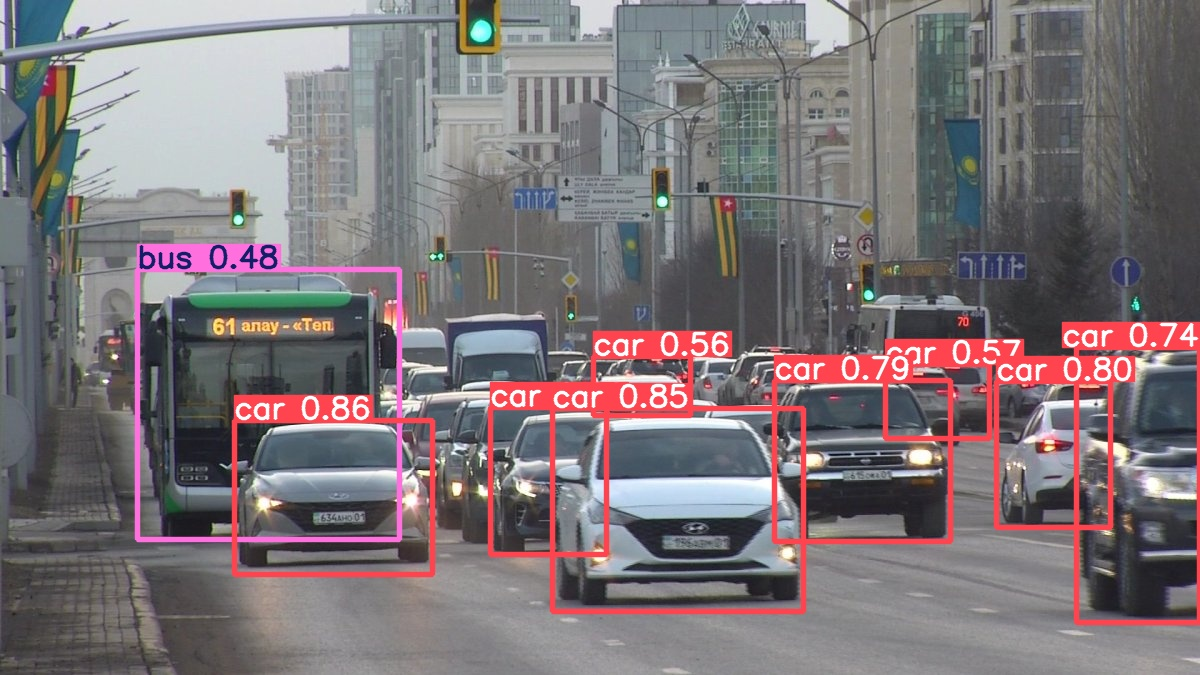

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
from pathlib import Path
import shutil

BEST_PT = "/content/drive/MyDrive/YOLO_runs/car_det_v8s_a100/weights/best.pt"
det_model = YOLO(BEST_PT)

IMG_DIR = "/content/drive/MyDrive/DATA_Test"
pred_det = det_model.predict(
    source=IMG_DIR,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True
)

det_dir = Path(pred_det[0].save_dir)
print("Colab output dir:", det_dir)

drive_save_dir = Path("/content/drive/MyDrive/YOLO_predictions")
drive_save_dir.mkdir(parents=True, exist_ok=True)

for item in det_dir.iterdir():
    shutil.copy(item, drive_save_dir / item.name)

print(f"All annotated results saved to: {drive_save_dir}")

for p in list(drive_save_dir.glob("*.jpg"))[:8]:
    display(Image(filename=str(p)))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


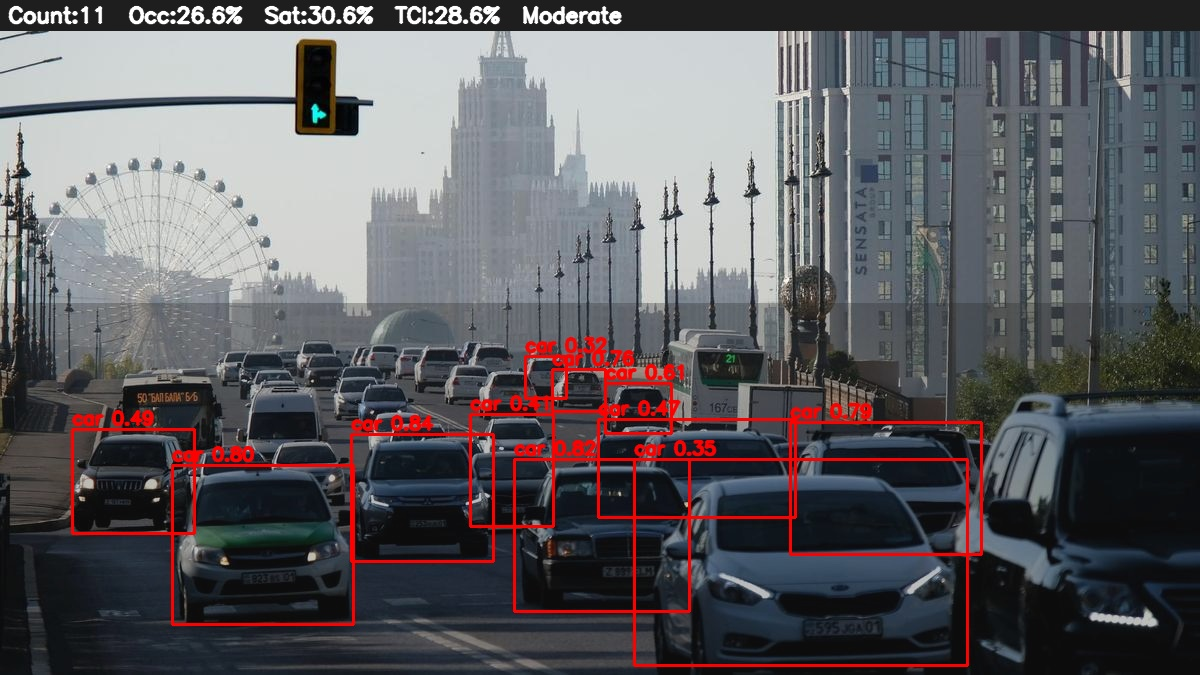

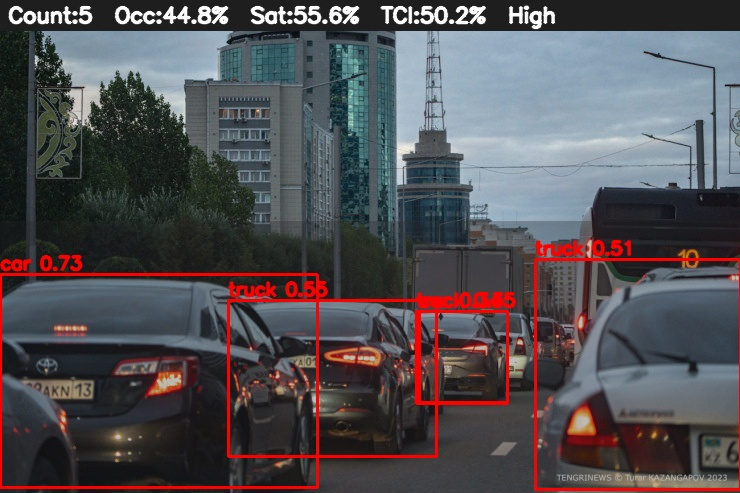

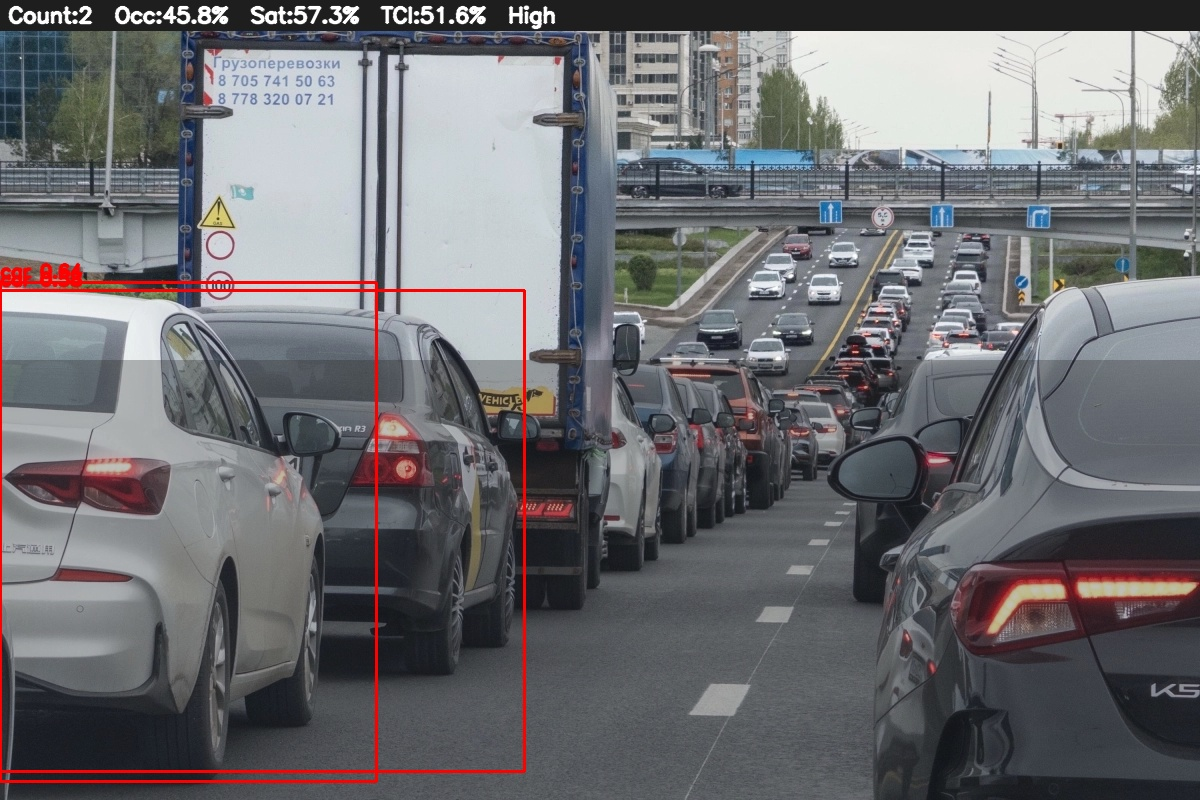

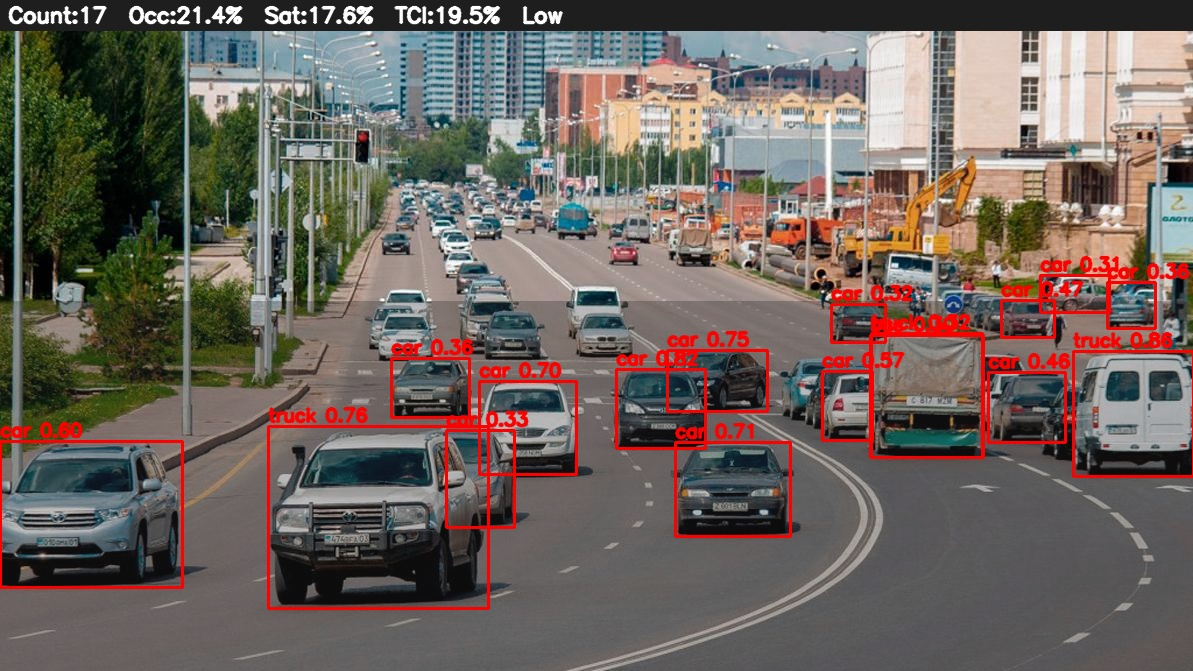

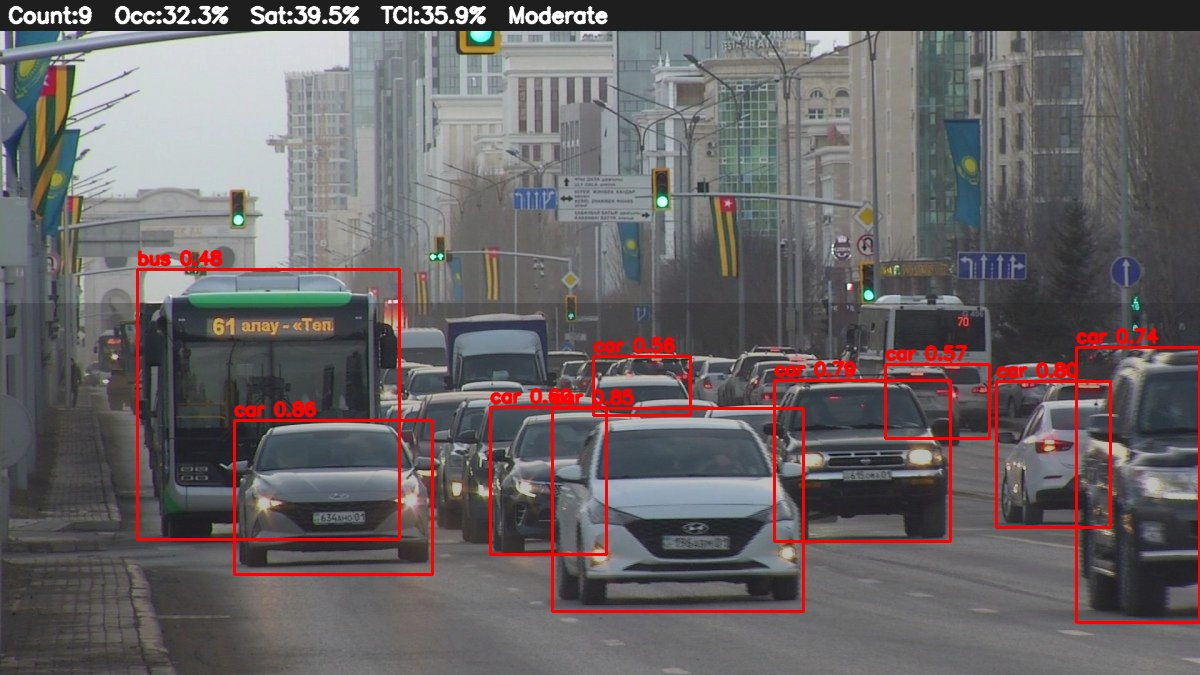

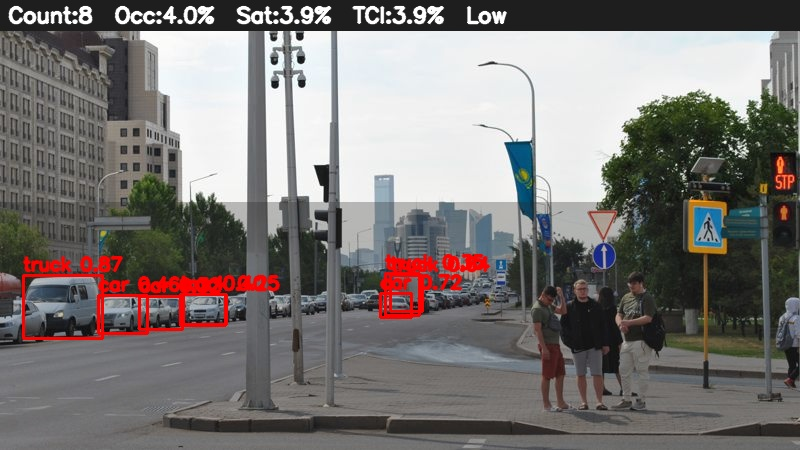

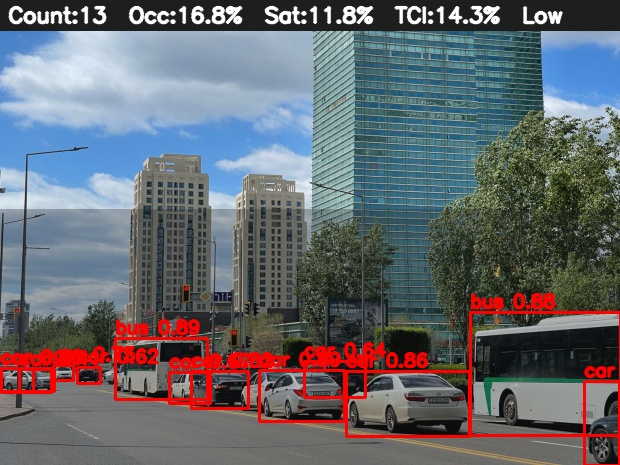

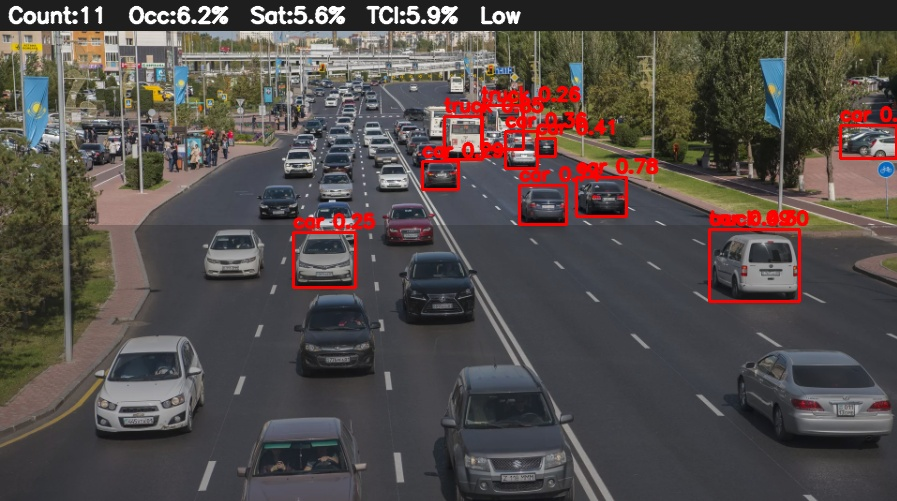

In [ ]:
from ultralytics import YOLO
import numpy as np, cv2, os, yaml, math, csv
from pathlib import Path
from google.colab import drive
from IPython.display import Image, display

drive.mount('/content/drive', force_remount=False)

BEST_PT = "/content/drive/MyDrive/YOLO_runs/car_det_v8s_a100/weights/best.pt"
IMG_DIR = Path("/content/drive/MyDrive/DATA_Test")
OUT_DIR = Path("/content/drive/MyDrive/Traffic_Estimates")
OUT_DIR.mkdir(parents=True, exist_ok=True)


VEHICLE_CLASSES = {"car", "truck", "bus", "van"}
CONF_THR = 0.25


model = YOLO(BEST_PT)


DATA_YAML = "/content/drive/MyDrive/Car_Detection_DATA/data.yaml"
with open(DATA_YAML, "r") as f:
    y = yaml.safe_load(f)
names = y.get("names", [])

name2id = {n:i for i, n in enumerate(names)}
veh_ids = [name2id[n] for n in names if n in VEHICLE_CLASSES]


def road_roi_mask(h, w, mode="bottom"):
    mask = np.zeros((h, w), np.uint8)
    if mode == "bottom":
        y0 = int(h * 0.45)
        mask[y0:h, 0:w] = 255
    return mask

def boxes_area_in_roi(boxes_xyxy, roi_mask):
    h, w = roi_mask.shape
    total = 0
    for x1, y1, x2, y2 in boxes_xyxy:
        x1, y1, x2, y2 = map(int, [x1, y1, x2, y2])
        x1 = np.clip(x1, 0, w-1); x2 = np.clip(x2, 0, w-1)
        y1 = np.clip(y1, 0, h-1); y2 = np.clip(y2, 0, h-1)
        if x2 <= x1 or y2 <= y1:
            continue
        roi_y1 = max(y1, np.where(roi_mask[:,0]>0)[0].min() if roi_mask.any() else 0)
        roi_y2 = y2
        if roi_mask[roi_y1:roi_y2, max(x1,0):min(x2,w)].size == 0:
            continue
        total += (x2-x1)*(y2-y1)
    return float(total)

def congestion_from_detections(img, det, roi_mask):
    h, w = img.shape[:2]
    boxes = det.boxes
    if boxes is None or boxes.shape[0] == 0:
        return dict(count=0, occupancy=0.0, saturation=0.0, tci=0.0, level="Low", img=img)


    keep = []
    for b in boxes:
        cls_id = int(b.cls.item())
        conf = float(b.conf.item())
        if conf >= CONF_THR and (len(veh_ids)==0 or cls_id in veh_ids):
            keep.append(b)
    if not keep:
        return dict(count=0, occupancy=0.0, saturation=0.0, tci=0.0, level="Low", img=img)

    xyxy = np.array([k.xyxy.cpu().numpy().ravel() for k in keep], dtype=np.float32)


    roi_area = float(roi_mask.sum()>0) and float(roi_mask.shape[0]*roi_mask.shape[1]*(roi_mask.max()>0))

    boxes_area = 0.0
    for x1,y1,x2,y2 in xyxy:
        x1=max(0,int(x1)); y1=max(0,int(y1)); x2=min(w,int(x2)); y2=min(h,int(y2))
        if x2>x1 and y2>y1:
            boxes_area += (x2-x1)*(y2-y1)
    occupancy = np.clip(boxes_area / (roi_mask.size if roi_area else (h*w)), 0, 1)


    areas = (xyxy[:,2]-xyxy[:,0])*(xyxy[:,3]-xyxy[:,1])
    med_area = float(np.median(areas)) if areas.size else (0.05*h*w)
    capacity = max(1.0, (roi_mask.size / max(med_area,1.0)) * 0.8)
    saturation = np.clip(len(xyxy) / capacity, 0, 1)

    tci = 0.5*occupancy + 0.5*saturation

    if   tci < 0.25: level = "Low"
    elif tci < 0.50: level = "Moderate"
    elif tci < 0.75: level = "High"
    else:            level = "Critical"


    vis = img.copy()
    overlay = vis.copy()
    overlay[roi_mask>0] = (0.7*overlay[roi_mask>0] + 0.3*np.array([40,40,40])).astype(np.uint8)
    vis = overlay

    for (x1,y1,x2,y2), b in zip(xyxy, keep):
        cls_id = int(b.cls.item()); conf = float(b.conf.item())
        color = (0,0,255)
        cv2.rectangle(vis, (int(x1),int(y1)), (int(x2),int(y2)), color, 2)
        label = f"{names[cls_id] if cls_id<len(names) else cls_id} {conf:.2f}"
        cv2.putText(vis, label, (int(x1), max(15,int(y1)-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

    text = f"Count:{len(xyxy)}  Occ:{occupancy*100:.1f}%  Sat:{saturation*100:.1f}%  TCI:{tci*100:.1f}%  {level}"
    cv2.rectangle(vis, (0,0), (vis.shape[1], 30), (30,30,30), -1)
    cv2.putText(vis, text, (8,22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2, cv2.LINE_AA)

    return dict(count=len(xyxy), occupancy=float(occupancy), saturation=float(saturation),
                tci=float(tci), level=level, img=vis)

csv_path = OUT_DIR / "traffic_metrics.csv"
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["image", "count", "occupancy_pct", "saturation_pct", "tci_pct", "level"])

    for img_path in sorted([p for p in IMG_DIR.iterdir() if p.suffix.lower() in {".jpg",".jpeg",".png"}]):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        roi_mask = road_roi_mask(h, w, mode="bottom")

        res = model.predict(source=str(img_path), imgsz=640, conf=CONF_THR, device=0, verbose=False)[0]
        metrics = congestion_from_detections(img, res, roi_mask)

        out_img = OUT_DIR / f"{img_path.stem}_traffic.jpg"
        cv2.imwrite(str(out_img), metrics["img"])

        writer.writerow([
            img_path.name,
            metrics["count"],
            round(metrics["occupancy"]*100, 2),
            round(metrics["saturation"]*100, 2),
            round(metrics["tci"]*100, 2),
            metrics["level"]
        ])


for p in list(OUT_DIR.glob("*_traffic.jpg")):
    display(Image(filename=str(p)))


ROI is the lower part of the frame (usually the roadway). You can replace the road polygon with your own if desired.

Occupancy is the total area of ​​detected vehicles in the ROI / the area of ​​the ROI.

Saturation is the ratio of the number of vehicles to the "occupancy" of the road. Occupancy is calculated as ROI area / median area of ​​one vehicle * 0.8.

TCI = 0.5 occupancy + 0.5 saturation.
Threshold levels:

 "<" 25% — Low

25–50% — Moderate

50–75% — High

 ">" 75% — Critical